In [1]:
import polars as pl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import duckdb

from pathlib import Path
from IPython.display import display

print("Semua library berhasil di-import.")
print("Polars version:", pl.__version__)
print("Pandas version:", pd.__version__)
print("DuckDB version:", duckdb.__version__)

Semua library berhasil di-import.
Polars version: 2.0.0
Pandas version: 3.1.0
DuckDB version: 2.0.0


In [2]:
# Lokasi dataset
DATA_PATH = "/home/jovyan/work/data/raw/cosmopedia_id.csv"

file_path = Path(DATA_PATH)

# Validasi keberadaan file
if not file_path.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {DATA_PATH}")

# Menghitung ukuran file
file_size_bytes = file_path.stat().st_size
file_size_mb = file_size_bytes / (1024 ** 2)
file_size_gb = file_size_bytes / (1024 ** 3)

print("DATASET INFORMATION")
print("=" * 40)
print("Nama file     :", file_path.name)
print("Lokasi file   :", file_path)
print(f"Ukuran (MB)   : {file_size_mb:,.2f} MB")
print(f"Ukuran (GB)   : {file_size_gb:,.3f} GB")
print("Status        : File ditemukan")

DATASET INFORMATION
Nama file     : cosmopedia_id.csv
Lokasi file   : /home/jovyan/work/data/raw/cosmopedia_id.csv
Ukuran (MB)   : 554.81 MB
Ukuran (GB)   : 0.542 GB
Status        : File ditemukan


In [3]:
# Membaca dataset dengan Lazy Evaluation
df = pl.scan_csv(
    DATA_PATH,
    infer_schema_length=10000,
    low_memory=True
)

print("Dataset berhasil dibaca menggunakan Polars.")

Dataset berhasil dibaca menggunakan Polars.


In [4]:
# Menampilkan schema dataset
schema = df.collect_schema()

print("DATASET SCHEMA")
print("=" * 40)

for column, dtype in schema.items():
    print(f"{column:<25} {dtype}")

DATASET SCHEMA
id                        Int64
prompt                    String
text                      String
token_length              Int64
audience                  String
format                    String
seed_data                 String
datasheet_global_id       Int64
created_at                String


In [5]:
# Menampilkan 10 baris pertama
sample_data = df.head(10).collect()

display(sample_data)

id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
i64,str,str,i64,str,str,str,i64,str
1,"""Berikut adalah ekstrak dari ha…","""Dahulu kala, ada sebuah agen y…",699,"""children""","""story""","""fineweb""",1,"""2026-02-18 07:35:54"""
24,"""Berikut kutipan dari sebuah ha…","""Suatu ketika, di sebuah negeri…",137,"""children""","""story""","""fineweb""",2,"""2026-02-18 08:19:23"""
25,"""Berikut kutipan dari sebuah ha…","""Di kota Popville, hiduplah ban…",93,"""children""","""story""","""fineweb""",3,"""2026-02-18 08:19:23"""
26,"""Berikut kutipan tentang chipmu…","""Di sebuah lingkungan yang tena…",76,"""children""","""story""","""fineweb""",4,"""2026-02-18 08:19:23"""
27,"""Berikut kutipan tentang terapi…","""Timmy pernah merasa sangat sed…",88,"""children""","""story""","""fineweb""",5,"""2026-02-18 08:19:23"""
28,"""Berikut kutipan tentang invest…","""Di negeri yang luas, seorang b…",57,"""children""","""story""","""fineweb""",6,"""2026-02-18 08:19:23"""
29,"""Berikut kutipan tentang kesela…","""Alice: Hei Bob, kalau jalan di…",61,"""children""","""dialogue""","""fineweb""",7,"""2026-02-18 08:19:23"""
30,"""Berikut kutipan tentang makana…","""Emma suka makanan manis. Bu Gu…",64,"""children""","""story""","""fineweb""",8,"""2026-02-18 08:19:23"""
31,"""Berikut kutipan tentang penyem…","""Alice: Aku sering susah tidur …",48,"""children""","""dialogue""","""fineweb""",9,"""2026-02-18 08:19:23"""


In [6]:
# Menampilkan 10 baris terakhir
last_data = df.tail(10).collect()

display(last_data)

id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
i64,str,str,i64,str,str,str,i64,str
120082,"""Berikut ini ekstrak dari halam…","""Bab 5: Karir di bidang Teknolo…",1219,"""middle_school_students""","""textbook""","""fineweb""",120059,"""2026-03-06 03:44:28"""
120083,"""Berikut ini ekstrak dari halam…","""Unit Mata Kuliah: Pemahaman Ma…",1384,"""middle_school_students""","""textbook""","""fineweb""",120060,"""2026-03-06 03:44:30"""
120084,"""Berikut ini ekstrak dari halam…","""Selamat datang di perjalanan m…",1196,"""middle_school_students""","""textbook""","""fineweb""",120061,"""2026-03-06 03:44:33"""
120085,"""Berikut ini ekstrak dari halam…","""Unit Kursus: Mendahulukan Sisw…",1457,"""middle_school_students""","""textbook_unconditionned_topic""","""fineweb""",120062,"""2026-03-06 03:44:35"""
120086,"""Berikut ini ekstrak dari halam…","""Pelajaran 10: Kebutuhan Diet K…",1272,"""middle_school_students""","""textbook""","""fineweb""",120063,"""2026-03-06 03:44:36"""
120087,"""Berikut ini ekstrak dari halam…","""Unit Kursus: Memahami Kekaisar…",1342,"""middle_school_students""","""textbook_unconditionned_topic""","""fineweb""",120064,"""2026-03-06 03:44:39"""
120088,"""Berikut ini ekstrak dari halam…","""Selamat datang di kursus kami …",1093,"""middle_school_students""","""textbook""","""fineweb""",120065,"""2026-03-06 03:44:41"""
120089,"""Berikut ini ekstrak dari halam…","""Pelajaran: Memahami Rehabilita…",1371,"""middle_school_students""","""textbook_unconditionned_topic""","""fineweb""",120066,"""2026-03-06 03:44:43"""
120090,"""Berikut ini ekstrak dari halam…","""Judul Bab: Monastisisme Cenobi…",1407,"""middle_school_students""","""textbook""","""fineweb""",120067,"""2026-03-06 03:44:45"""


In [7]:
# Menghitung jumlah baris
jumlah_baris = df.select(
    pl.len()
).collect().item()

# Menghitung jumlah kolom
jumlah_kolom = len(schema.names())

print("DATASET DIMENSION")
print("=" * 40)
print(f"Jumlah baris : {jumlah_baris:,}")
print(f"Jumlah kolom : {jumlah_kolom}")

DATASET DIMENSION
Jumlah baris : 120,068
Jumlah kolom : 9


In [8]:
# Ringkasan Informasi Dataset
print("DATASET SUMMARY")
print("=" * 40)

print(f"Nama dataset       : Cosmopedia Indonesia")
print(f"Jumlah observasi   : {jumlah_baris:,}")
print(f"Jumlah variabel    : {jumlah_kolom}")
print(f"Ukuran file        : {file_size_mb:,.2f} MB")

print("\nDaftar kolom:")
for i, column in enumerate(schema.names(), start=1):
    print(f"{i}. {column}")

DATASET SUMMARY
Nama dataset       : Cosmopedia Indonesia
Jumlah observasi   : 120,068
Jumlah variabel    : 9
Ukuran file        : 554.81 MB

Daftar kolom:
1. id
2. prompt
3. text
4. token_length
5. audience
6. format
7. seed_data
8. datasheet_global_id
9. created_at


In [9]:
# Membuat tabel informasi tipe data
column_info = pl.DataFrame({
    "Nama Kolom": schema.names(),
    "Tipe Data": [str(dtype) for dtype in schema.dtypes()]
})

display(column_info)

Nama Kolom,Tipe Data
str,str
"""id""","""Int64"""
"""prompt""","""String"""
"""text""","""String"""
"""token_length""","""Int64"""
"""audience""","""String"""
"""format""","""String"""
"""seed_data""","""String"""
"""datasheet_global_id""","""Int64"""
"""created_at""","""String"""


In [10]:
# Pemeriksaan Missing Values
missing_values = df.select([
    pl.col(column).null_count().alias(column)
    for column in schema.names()
]).collect()

display(missing_values)

id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,0


In [11]:
# Pemeriksaan Empty String
string_columns = [
    column
    for column, dtype in schema.items()
    if dtype == pl.String
]

empty_values = df.select([
    (
        pl.col(column)
        .str.strip_chars()
        .eq("")
        .fill_null(False)
        .sum()
    ).alias(column)
    for column in string_columns
]).collect()

display(empty_values)

prompt,text,audience,format,seed_data,created_at
u32,u32,u32,u32,u32,u32
0,0,1,1,1,0


In [12]:
# Presentase Missing Values
missing_percentage = df.select([
    (
        pl.col(column).null_count() / pl.len() * 100
    ).alias(column)
    for column in schema.names()
]).collect()

display(missing_percentage)

id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
f64,f64,f64,f64,f64,f64,f64,f64,f64
0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [13]:
# Menghitung Nilai unik
unique_values = df.select([
    pl.col(column).n_unique().alias(column)
    for column in schema.names()
]).collect()

display(unique_values)

id,prompt,text,token_length,audience,format,seed_data,datasheet_global_id,created_at
u32,u32,u32,u32,u32,u32,u32,u32,u32
120068,119817,120067,1559,4,9,6,120068,119908


In [14]:
# Mengidentifikasi kolom numerik
numeric_columns = [
    column
    for column, dtype in schema.items()
    if dtype.is_numeric()
]

print("Kolom numerik:", numeric_columns)

# Menghitung statistik deskriptif
if numeric_columns:
    numeric_statistics = df.select([
        expr
        for column in numeric_columns
        for expr in [
            pl.col(column).min().alias(f"{column}_min"),
            pl.col(column).max().alias(f"{column}_max"),
            pl.col(column).mean().alias(f"{column}_mean"),
            pl.col(column).median().alias(f"{column}_median"),
            pl.col(column).std().alias(f"{column}_std")
        ]
    ]).collect()

    display(numeric_statistics)

else:
    print("Tidak terdapat kolom numerik.")

Kolom numerik: ['id', 'token_length', 'datasheet_global_id']


id_min,id_max,id_mean,id_median,id_std,token_length_min,token_length_max,token_length_mean,token_length_median,token_length_std,datasheet_global_id_min,datasheet_global_id_max,datasheet_global_id_mean,datasheet_global_id_median,datasheet_global_id_std
i64,i64,f64,f64,f64,i64,i64,f64,f64,f64,i64,i64,f64,f64,f64
1,120091,60057.499217,60057.5,34660.791753,36,2787,1187.939651,1168.0,194.61858,1,120068,60034.5,60034.5,34660.790398


In [15]:
# Analisis Panjang Text
text_statistics = df.select([
    pl.col("prompt").str.len_chars().mean().alias("rata_rata_prompt"),
    pl.col("prompt").str.len_chars().min().alias("minimum_prompt"),
    pl.col("prompt").str.len_chars().max().alias("maksimum_prompt"),

    pl.col("text").str.len_chars().mean().alias("rata_rata_text"),
    pl.col("text").str.len_chars().min().alias("minimum_text"),
    pl.col("text").str.len_chars().max().alias("maksimum_text")
]).collect()

display(text_statistics)

rata_rata_prompt,minimum_prompt,maksimum_prompt,rata_rata_text,minimum_text,maksimum_text
f64,u32,u32,f64,u32,u32
1785.361887,106,3829,2964.115085,18,9789


In [16]:
# Statistik token length
token_statistics = df.select([
    pl.col("token_length").mean().alias("rata_rata_token"),
    pl.col("token_length").min().alias("token_minimum"),
    pl.col("token_length").max().alias("token_maksimum"),
    pl.col("token_length").median().alias("token_median"),
    pl.col("token_length").std().alias("token_standar_deviasi")
]).collect()

display(token_statistics)

rata_rata_token,token_minimum,token_maksimum,token_median,token_standar_deviasi
f64,i64,i64,f64,f64
1187.939651,36,2787,1168.0,194.61858


In [17]:
# Distribusi Audience
audience_distribution = (
    df.group_by("audience")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
    .collect()
)

display(audience_distribution)

audience,jumlah_data
str,u32
"""children""",64989
"""middle_school_students""",33078
"""young_children""",22000
"""""",1


In [18]:
# Distribusi Format
format_distribution = (
    df.group_by("format")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
    .collect()
)

display(format_distribution)

format,jumlah_data
str,u32
"""story""",36230
"""dialogue""",28758
"""textbook""",24508
"""story_children""",17989
"""textbook_unconditionned_topic""",8521
"""textbook_narrative""",3562
"""e-learning_module""",498
"""Dialogue""",1
"""""",1


In [19]:
# Distribusi seed_data
seed_distribution = (
    df.group_by("seed_data")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
    .head(10)
    .collect()
)

display(seed_distribution)

seed_data,jumlah_data
str,u32
"""fineweb""",98018
"""openhermes2.5""",10021
"""ultrachat""",7968
"""stanford""",3562
"""openstax""",498
"""""",1


In [20]:
# Pemeriksaan Duplikasi
duplicate_summary = df.select([
    pl.len().alias("total_baris"),
    pl.col("id").n_unique().alias("id_unik"),
    (
        pl.len() - pl.col("id").n_unique()
    ).alias("jumlah_id_duplikat")
]).collect()

display(duplicate_summary)

total_baris,id_unik,jumlah_id_duplikat
u32,u32,u32
120068,120068,0


In [21]:
# Pemeriksaan created_at
date_summary = df.select([
    pl.col("created_at").min().alias("tanggal_terawal"),
    pl.col("created_at").max().alias("tanggal_terakhir"),
    pl.col("created_at").null_count().alias("tanggal_kosong")
]).collect()

display(date_summary)

tanggal_terawal,tanggal_terakhir,tanggal_kosong
str,str,u32
"""2026-02-18 07:35:54""","""2026-03-06 03:44:48""",0


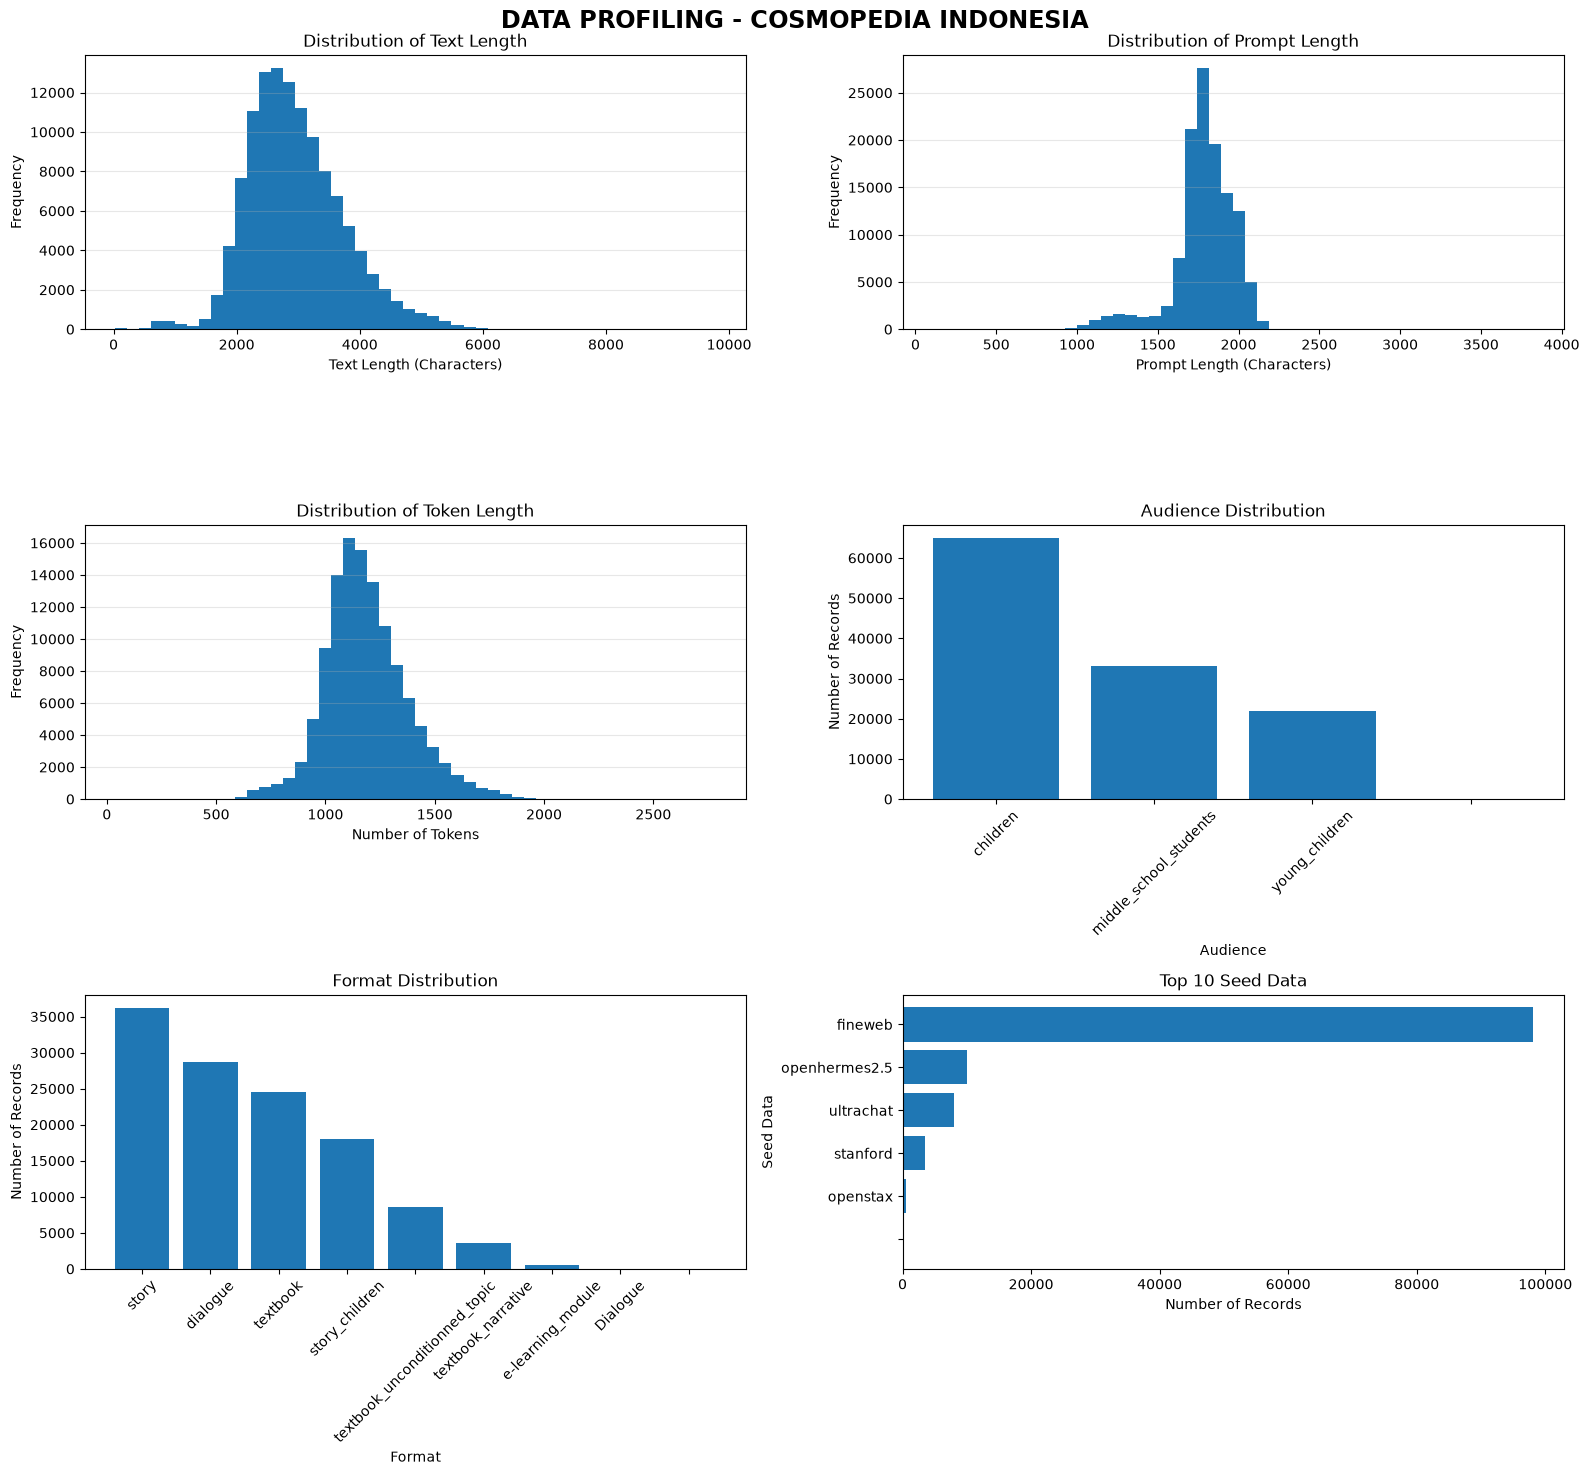

In [22]:
# Mengambil kolom yang dibutuhkan untuk visualisasi
visual_data = df.select([
    pl.col("text").str.len_chars().alias("text_length"),
    pl.col("prompt").str.len_chars().alias("prompt_length"),
    pl.col("token_length"),
    pl.col("audience"),
    pl.col("format"),
    pl.col("seed_data")
]).collect()

# Membuat dashboard visualisasi
fig, axes = plt.subplots(3, 2, figsize=(16, 15))

# 1. Distribusi panjang teks
text_lengths = visual_data["text_length"].drop_nulls().to_numpy()

axes[0, 0].hist(text_lengths, bins=50)
axes[0, 0].set_title("Distribution of Text Length")
axes[0, 0].set_xlabel("Text Length (Characters)")
axes[0, 0].set_ylabel("Frequency")
axes[0, 0].grid(axis="y", alpha=0.3)

# 2. Distribusi panjang prompt
prompt_lengths = visual_data["prompt_length"].drop_nulls().to_numpy()

axes[0, 1].hist(prompt_lengths, bins=50)
axes[0, 1].set_title("Distribution of Prompt Length")
axes[0, 1].set_xlabel("Prompt Length (Characters)")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].grid(axis="y", alpha=0.3)

# 3. Distribusi token length
token_lengths = visual_data["token_length"].drop_nulls().to_numpy()

axes[1, 0].hist(token_lengths, bins=50)
axes[1, 0].set_title("Distribution of Token Length")
axes[1, 0].set_xlabel("Number of Tokens")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].grid(axis="y", alpha=0.3)

# 4. Distribusi audience
audience_data = (
    visual_data
    .group_by("audience")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
)

axes[1, 1].bar(
    audience_data["audience"].cast(pl.String).to_list(),
    audience_data["jumlah_data"].to_list()
)
axes[1, 1].set_title("Audience Distribution")
axes[1, 1].set_xlabel("Audience")
axes[1, 1].set_ylabel("Number of Records")
axes[1, 1].tick_params(axis="x", rotation=45)

# 5. Distribusi format
format_data = (
    visual_data
    .group_by("format")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
)

axes[2, 0].bar(
    format_data["format"].cast(pl.String).to_list(),
    format_data["jumlah_data"].to_list()
)
axes[2, 0].set_title("Format Distribution")
axes[2, 0].set_xlabel("Format")
axes[2, 0].set_ylabel("Number of Records")
axes[2, 0].tick_params(axis="x", rotation=45)

# 6. Top 10 seed data
seed_data = (
    visual_data
    .group_by("seed_data")
    .agg(pl.len().alias("jumlah_data"))
    .sort("jumlah_data", descending=True)
    .head(10)
    .sort("jumlah_data")
)

axes[2, 1].barh(
    seed_data["seed_data"].cast(pl.String).to_list(),
    seed_data["jumlah_data"].to_list()
)
axes[2, 1].set_title("Top 10 Seed Data")
axes[2, 1].set_xlabel("Number of Records")
axes[2, 1].set_ylabel("Seed Data")

# Pengaturan dashboard
fig.suptitle(
    "DATA PROFILING - COSMOPEDIA INDONESIA",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [23]:
# Analisis DuckDB
con = duckdb.connect(database=":memory:")

duckdb_summary = con.execute(
    """
    SELECT
        COUNT(*) AS jumlah_baris,
        COUNT(DISTINCT id) AS jumlah_id_unik,
        AVG(token_length) AS rata_rata_token,
        MIN(token_length) AS token_minimum,
        MAX(token_length) AS token_maksimum
    FROM read_csv_auto(?)
    """,
    [DATA_PATH]
).df()

display(duckdb_summary)

,jumlah_baris,jumlah_id_unik,rata_rata_token,token_minimum,token_maksimum
0,120068,120068,1187.939651,36,2787


In [24]:
# Query distribusi audience menggunakan DuckDB
duckdb_audience = con.execute(
    """
    SELECT
        audience,
        COUNT(*) AS jumlah_data
    FROM read_csv_auto(?)
    GROUP BY audience
    ORDER BY jumlah_data DESC
    """,
    [DATA_PATH]
).df()

display(duckdb_audience)

,audience,jumlah_data
0,children,64989
1,middle_school_students,33078
2,young_children,22000
3,NaN,1


In [25]:
# Query distribusi format menggunakan DuckDB
duckdb_format = con.execute(
    """
    SELECT
        format,
        COUNT(*) AS jumlah_data
    FROM read_csv_auto(?)
    GROUP BY format
    ORDER BY jumlah_data DESC
    """,
    [DATA_PATH]
).df()

display(duckdb_format)

,format,jumlah_data
0,story,36230
1,dialogue,28758
2,textbook,24508
3,story_children,17989
4,textbook_unconditionned_topic,8521
5,textbook_narrative,3562
6,e-learning_module,498
7,NaN,1
8,Dialogue,1


# KESIMPULAN DATA PROFILING

Berdasarkan proses data profiling yang telah dilakukan,
diperoleh beberapa informasi mengenai dataset Cosmopedia Indonesia.

1. Dataset memiliki struktur yang terdiri dari 9 kolom,
   yaitu id, prompt, text, token_length, audience, format,
   seed_data, datasheet_global_id, dan created_at.

2. Kolom prompt dan text berisi informasi berbentuk teks,
   sedangkan id, token_length, dan datasheet_global_id
   merupakan kolom numerik.

3. Pemeriksaan missing values dilakukan untuk mengetahui
   keberadaan nilai kosong pada setiap kolom.

4. Pemeriksaan empty string dilakukan untuk mengidentifikasi
   data teks yang kosong atau hanya berisi spasi.

5. Statistik deskriptif digunakan untuk mengetahui karakteristik
   kolom numerik.

6. Analisis panjang teks dan token length dilakukan untuk
   memahami karakteristik ukuran teks dalam dataset.

7. Distribusi audience, format, dan seed_data digunakan
   untuk mengetahui persebaran karakteristik data.

8. Pemeriksaan duplikasi dilakukan berdasarkan kolom id.

9. Polars digunakan untuk pembacaan dan pengolahan data
   dengan pendekatan Lazy Evaluation.

10. DuckDB digunakan untuk melakukan query analitik
    terhadap dataset.

Hasil data profiling ini akan digunakan sebagai dasar
untuk proses data cleaning pada notebook berikutnya.